In [3]:
import pandas as pd
from tensorflow import keras
from sklearn.model_selection import train_test_split

# Yêu cầu 1: Đọc dữ liệu từ file diabetes.csv. Chia dữ liệu thành 2 phần: training (85%) và phần còn lại cho testing (15%).
# 1.1. Đọc file .csv sử dụng pandas
columns = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
df = pd.read_csv('/content/drive/MyDrive/Học máy cơ bản/Practice02/diabetes.csv', usecols = columns)

# 1.2. Chia dữ liệu: train (85% = 653) and test (15% = 115)
X = df[['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']]

y = df['Outcome']
train_size = 653
X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

# 1.3. Mã hóa One-hot (One-hot encoding)
y_train_onehot = keras.utils.to_categorical(y_train, 2)
y_test_onehot = keras.utils.to_categorical(y_test, 2)

print("Number of Training samples:", len(X_train))
print("Number of Testing samples:", len(X_test))

Number of Training samples: 653
Number of Testing samples: 115


In [4]:
# Yêu cầu 2: Xây dựng mạng nơ-ron:
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential

# 2.1. Xây dựng mạng nơ-ron nông với 2 lớp ẩn
def modelNN1():

    model = Sequential()

    # Xây dựng mạng: 1 Input + 2 Hidden + 1 Output
    model.add(Dense(16, input_dim=8, activation='relu'))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(2, activation='softmax'))

    return model

# Xây dựng mạng nơ-ron sâu với nhiều lớp ẩn
def modelNN2():

    model2 = Sequential()

    # Xây dựng mạng: 1 Input + 4 Hidden + 1 Output
    model2.add(Dense(8, input_dim=8, activation='relu'))
    model2.add(Dense(16, activation='relu'))
    model2.add(Dense(32, activation='relu'))
    model2.add(Dense(8, activation='relu'))
    model2.add(Dense(2, activation='softmax'))

    return model2

# 2.2 Chọn model (1 lớp ẩn hay nhiều lớp ẩn)
model = modelNN1()
model2 = modelNN2()

# 2.3. Hiển thị thông tin model
model.summary()
model2.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 754 (2.95 KB)

 Trainable params: 754 (2.95 KB)

...

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 8)              │           264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,042 (4.07 KB)

 Trainable params: 1,042 (4.07 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Yêu cầu 3: Lựa chọn hàm loss và tối ưu hoá cho cả 2 mô hình.
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
model2.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

Epoch 1/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.4962 - loss: 2.2957 - val_accuracy: 0.4198 - val_loss: 1.1786
Epoch 2/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5364 - loss: 1.0754 - val_accuracy: 0.6718 - val_loss: 0.9149
Epoch 3/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5670 - loss: 0.8867 - val_accuracy: 0.5191 - val_loss: 0.8563
Epoch 4/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6130 - loss: 0.7973 - val_accuracy: 0.5725 - val_loss: 0.8234
Epoch 5/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6207 - loss: 0.7767 - val_accuracy: 0.6031 - val_loss: 0.8109
Epoch 6/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6475 - loss: 0.7322 - val_accuracy: 0.6412 - val_loss: 0.7598
Epoch 7/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6552 - loss: 0.6978 - val_accuracy: 0.7099 - val_loss: 0.7150
Epoch 8/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6724 - loss: 0.6796 - val_accuracy: 0.6412 - val_los

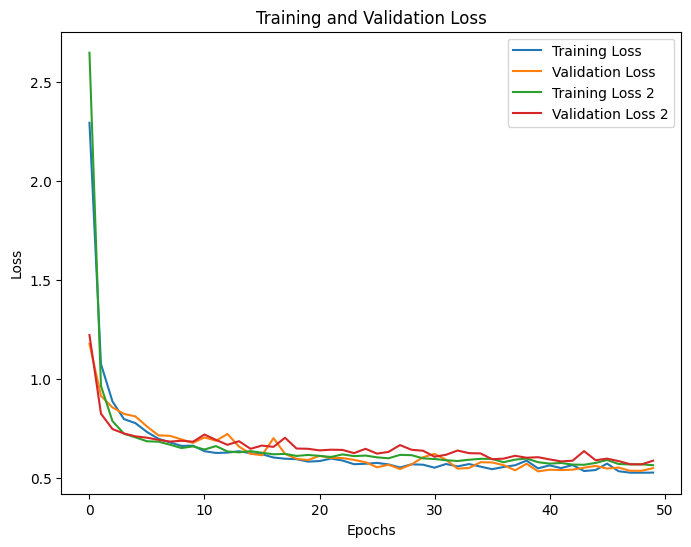

In [6]:
# Yêu cầu 4: Tiến thành training mạng nơ-ron đã xây dựng trên tập dữ liệu đã được xử lý ở bước 1 với 50 epochs và lưu lại các model đã huấn luyện.
from tensorflow import keras
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.layers import Dropout

# 4.1. Training model (có nhiều tuỳ chọn). Một số tham số:
history = model.fit(X_train, y_train_onehot, validation_split=0.2, epochs=50, batch_size=16)

history2 = model2.fit(X_train, y_train_onehot, validation_split=0.2, epochs=50, batch_size=16)

# 4.2. Lưu model
model.save('modelNN1_model.h5')
model2.save('modelNN2_model.h5')

# 4.3. Hiển thị Training and Validation Loss
plt.figure(figsize=(8, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.plot(history2.history['loss'], label='Training Loss 2')
plt.plot(history2.history['val_loss'], label='Validation Loss 2')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [7]:
# Yêu cầu 5: Đánh giá model đã được training trên tập testing. So sánh xem mô hình nào tốt hơn: nông hay sâu?
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 5.1. Hiển thị kết quả (accuracy) trên tập testing
test_loss, test_acc = model.evaluate(X_test, y_test_onehot)
print('Test loss:', test_loss)
print('Test accuracy:', test_acc)

test_loss2, test_acc2 = model2.evaluate(X_test, y_test_onehot)
print('Test loss:', test_loss2)
print('Test accuracy:', test_acc2)

from tensorflow.keras.models import Sequential, Model, load_model, Sequential
# 5.2. Load lại model
model_loaded1 = load_model('modelNN1_model.h5')
model_loaded2 = load_model('modelNN2_model.h5')

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6348 - loss: 0.7252 
Test loss: 0.7251834273338318
Test accuracy: 0.634782612323761
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6348 - loss: 0.6727


Test loss: 0.6726657152175903
Test accuracy: 0.634782612323761


In [10]:
# Yêu cầu 6: Sử dụng trained model (lưu ở bước 4) để đánh giá trên trên tập testing (20%) được xử lý ở bước 1.
X = df.iloc[:, :-1].values #lấy tất cả dòng trừ cột cuối
y = df.iloc[:, -1].values #chỉ lấy các dòng của cột cuối

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

y_train_onehot = keras.utils.to_categorical(y_train, 2)
y_test_onehot = keras.utils.to_categorical(y_test, 2)

print("Number of Training samples: ", len(X_train))
print("Number of Testing samples: ", len(X_test))

import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

test_loss1, test_acc1 = model.evaluate(X_test, y_test_onehot)
print("ModelNN1: ")
print("Test loss: ", test_loss1)
print("Test accuracy: ", test_acc1)

test_loss2, test_acc2 = model2.evaluate(X_test, y_test_onehot)
print("ModelNN2: ")
print("Test loss: ", test_loss2)
print("Test accuracy: ", test_acc2)

Number of Training samples:  614
Number of Testing samples:  154
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7273 - loss: 0.5093 
ModelNN1: 
Test loss:  0.5092582106590271
Test accuracy:  0.7272727489471436
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7273 - loss: 0.5416 
ModelNN2: 
Test loss:  0.5415729284286499
Test accuracy:  0.7272727489471436


In [ ]:
# Yêu cầu 7*: Xây dựng ứng dụng thực tế sử dụng trained model.
